# Classification

### Iris Data
**Target (output)** <br>
The species of the flower, encoded as: <br>
0: Iris Setosa <br>
1: Iris Versicolor <br>
2: Iris Virginica <br> 
**Features (inputs)** <br>
Four numerical measurements for each flower: <br>
Sepal length (cm) <br>
Sepal width (cm) <br>
Petal length (cm) <br>
Petal width (cm) 


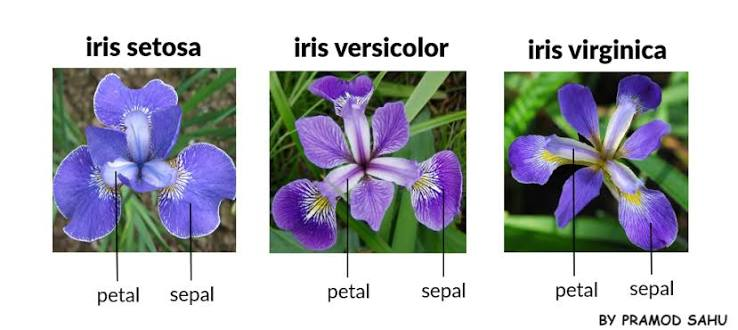

## Import Libraries 

In [ ]:
#pip install -U scikit-learn

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

### 1. Import Dataset

In [3]:
df = pd.read_csv("iris.csv")

### 2. Clean Missing Values

In [4]:
#missing values
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

### 3. EDA

In [5]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [6]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


<Axes: >

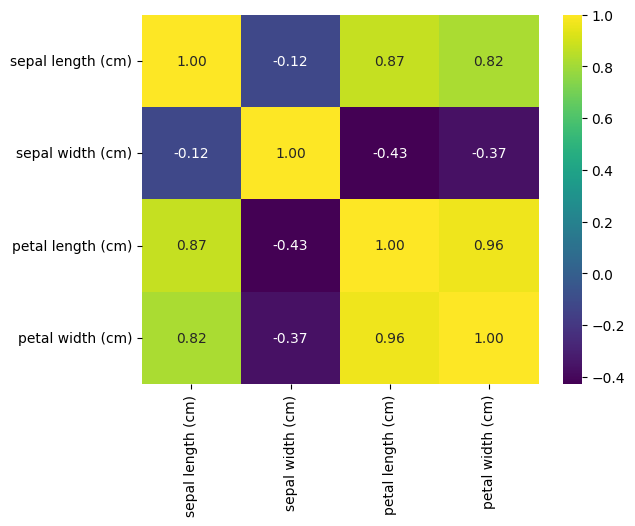

In [7]:
#correlation matrix
cor = df[["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]].corr()
sns.heatmap(cor, annot= True, fmt = ".2f", cmap = "viridis")

In [8]:
df["target"].value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

#### 4. Features and Target

In [9]:
X = df.iloc[:,:-1] #features
y = df.iloc[:,-1] #target

-------
------

#### A. Decision Tree

In [29]:
#Train and Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)
#model
model = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=0)
DecT = model.fit(X_train, y_train)

In [12]:
y

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: target, Length: 150, dtype: int64

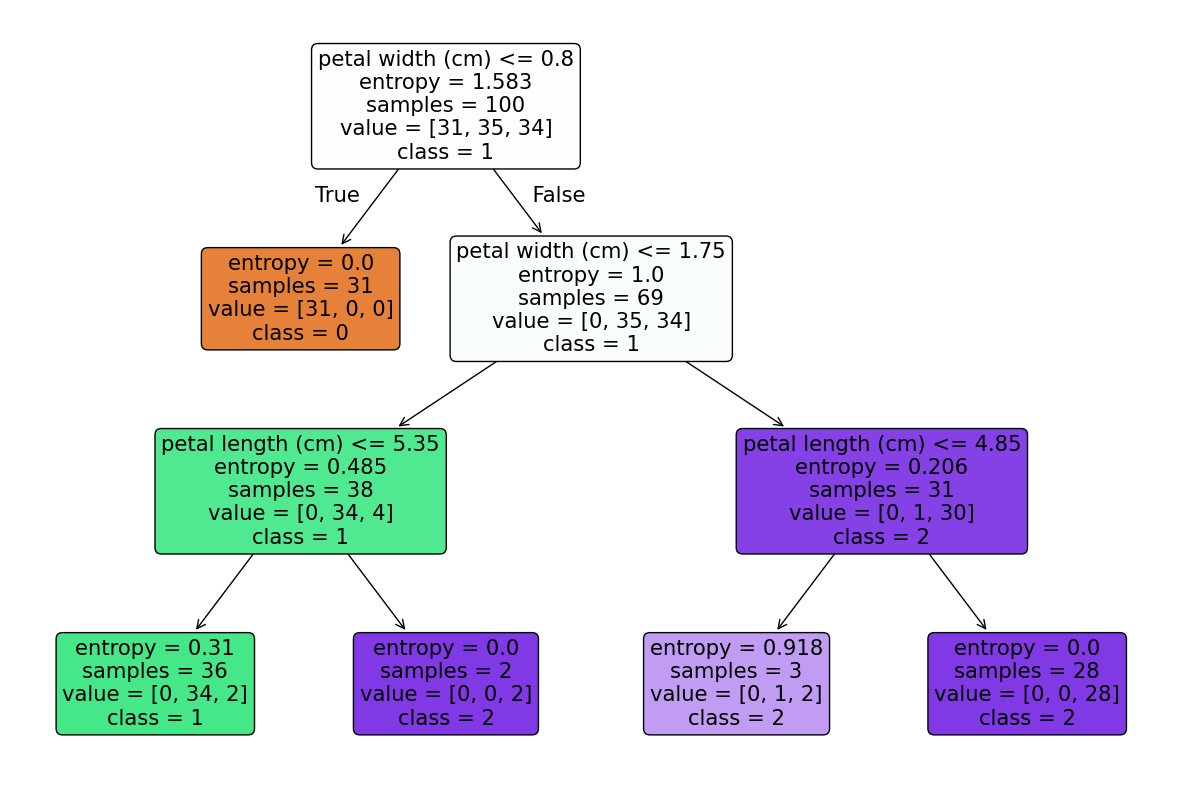

In [15]:
plt.figure(figsize=(15, 10))
plot_tree(
    DecT, feature_names=list(X.columns), class_names=[
        str(c) for c in y.unique()
    ], filled=True,
    rounded=True,)
plt.show()

In [22]:
pred_tree = DecT.predict(X_test)

### B. Logistic Regression

In [27]:
#Train and Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)
#model
model = LogisticRegression()
Logistic = model.fit(X_train, y_train)

In [23]:
pred_log = Logistic.predict(X_test)

**Compare Models**

In [25]:
cls_models = [Logistic, DecT]
cls_names = ["Logistic Regression", "Decision Tree"]

cls_results = []

# 2. Loop through each model to calculate classification metrics
for name, model in zip(cls_names, cls_models):
    preds = model.predict(X_test)  # Ensure X_test belongs to your Iris dataset
    
    cls_results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds, average='macro'), 4),
        "Recall": round(recall_score(y_test, preds, average='macro'), 4),
    })

# 3. Create and display the table
df_classification_table = pd.DataFrame(cls_results)
df_classification_table

,Model,Accuracy,Precision,Recall
0,Logistic Regression,1.00,1.0000,1.0000
1,Decision Tree,0.98,0.9792,0.9792


**Confusion Matrix DECT**

In [31]:
y_pred = DecT.predict(X_test)

In [32]:
confusion_matrix(y_test, y_pred) 

array([[19,  0,  0],
       [ 0, 15,  0],
       [ 0,  1, 15]])

## 5. Predict Unkown Values

In [33]:
dt = pd.read_csv("iris_un.csv")

In [34]:
dt.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [35]:
species_predictions = DecT.predict(dt)

In [36]:
species_predictions

array([0, 0, 0, 0, 0, 0, 0, 0, 0])

In [55]:
def avg(v1,v2):
    M = (v1*2+v2*1)/3
    print("The student mark is:", M)
    if M >=10:
        print("Pass")
        if M == 16:
            print("Pass and Gift")
    elif M == 9.80:
        print("Help")
    else:
        print("Fail")

In [54]:
avg(18,18)

The student mark is: 18.0
Pass


**Logical Operators**

In [56]:
Height = True #1.70
Weight = True #75
if Height and Weight:
    print("Pass")

Pass


In [57]:
Module1 = 9
Module2 = 12
if Module1 >=10 and Module2>=10:
    print("Pass")
else:
    print("Fail")

Fail


In [58]:
Module1 = 9
Module2 = 12
if Module1 >=10 or Module2>=10:
    print("Pass")
else:
    print("Fail")

Pass


In [62]:
Years = 5
Mark = 15
Age = 21
Certeficate = 5
if Years <= 5 and Mark >= 15 and (Age < 21 or Certeficate >=5):
    print("Win")
else:
    print("Lose")

Win


In [61]:
Years = 5
Mark = 15
Age = 21
Certeficate = 5
if Years <= 5 and not Mark >= 15 and (Age < 21 or Certeficate >=5):
    print("Win")
else:
    print("Lose")

Lose


In [86]:
data = pd.read_csv("airline_passengers.csv")

In [87]:
data.head()

,Month,Thousands of Passengers
0,1949-01,112.0
1,1949-02,118.0
2,1949-03,132.0
3,1949-04,129.0
4,1949-05,121.0


In [83]:
data.set_index("Month", inplace = True)

In [84]:
data.info()

<class 'pandas.DataFrame'>
Index: 145 entries, 1949-01 to International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60
Data columns (total 1 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Thousands of Passengers  144 non-null    float64
dtypes: float64(1)
memory usage: 2.3+ KB


In [85]:
data["Month"] = pd.to_datetime(data["Month"])

KeyError: 'Month'

In [88]:
data["First"] = data["Thousands of Passengers"] - data["Thousands of Passengers"].shift(1)

In [89]:
data.head()

,Month,Thousands of Passengers,First
0,1949-01,112.0,NaN
1,1949-02,118.0,6.0
2,1949-03,132.0,14.0
3,1949-04,129.0,-3.0
4,1949-05,121.0,-8.0


In [92]:
data["Second_M"] = data["Thousands of Passengers"] - data["Thousands of Passengers"].shift(2)

In [93]:
data.head()

,Month,Thousands of Passengers,First,Second,Second_M
0,1949-01,112.0,NaN,NaN,NaN
1,1949-02,118.0,6.0,NaN,NaN
2,1949-03,132.0,14.0,20.0,20.0
3,1949-04,129.0,-3.0,11.0,11.0
4,1949-05,121.0,-8.0,-11.0,-11.0


In [94]:
data["Second_D"] = data["First"] - data["First"].shift(1)

In [95]:
data.head()

,Month,Thousands of Passengers,First,Second,Second_M,Second_D
0,1949-01,112.0,NaN,NaN,NaN,NaN
1,1949-02,118.0,6.0,NaN,NaN,NaN
2,1949-03,132.0,14.0,20.0,20.0,8.0
3,1949-04,129.0,-3.0,11.0,11.0,-17.0
4,1949-05,121.0,-8.0,-11.0,-11.0,-5.0


In [98]:
data["Second_C"] = data["Second_M"] = data["Thousands of Passengers"].diff(2)

In [97]:
data.head()

,Month,Thousands of Passengers,First,Second,Second_M,Second_D,Second_C
0,1949-01,112.0,NaN,NaN,NaN,NaN,NaN
1,1949-02,118.0,6.0,NaN,NaN,NaN,NaN
2,1949-03,132.0,14.0,20.0,20.0,8.0,20.0
3,1949-04,129.0,-3.0,11.0,11.0,-17.0,11.0
4,1949-05,121.0,-8.0,-11.0,-11.0,-5.0,-11.0
